# Неделя 10. Логистическая регрессия и kNN: вероятность, расстояние, решение

**Tech Orda · Gizatov A. S. · beginner ML/AI · Python 3**

**Практика:** 108 минут практики (2 × 54 минуты). На неделе также 72 минуты разбора теории: всего
2 занятия × 90 минут = 4 академических часа. Домашнее задание выполняется отдельно.

**Результат:** построить бинарный классификатор культивара 0, сравнить логистическую модель и kNN, выбрать порог на validation и объяснить роль масштаба признаков.

Ячейки идут от постановки задачи и описательной аналитики к алгоритму,
проверке и интерпретации. Сначала предскажите результат ячейки, затем запускайте.
Данные уже находятся в `../datasets`; интернет, GPU и API-ключи не нужны.
Запуск: **Restart Kernel → Run All**. Зависимости устанавливаются заранее
по инструкции в корне репозитория; из notebook ничего не устанавливается.


In [1]:
# Ограничиваем число потоков: небольшие учебные задачи запускаются на CPU.
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
# Поддерживается запуск из корня репозитория, practice/ и homework/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "course_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте notebook внутри клонированного репозитория")
WEEK = ROOT / 'week_10_logistic_knn'
DATA = WEEK / "datasets"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                      "grid.alpha": 0.2, "font.size": 10})


## Данные и граница между обучением и проверкой

`sample_id` нужен для аудита разделения, **не для обучения**. `target` — ответ;
его нельзя включать в признаки. Проверки схемы выполняем для всего CSV,
а содержательный EDA — только для обучающей части. Test откроем после фиксации
модели и правила принятия решений. Фиксированный seed делает опыт повторяемым,
но не превращает одно разделение в доказательство универсальности результата.


In [2]:
df = pd.read_csv(DATA / 'wine.csv').set_index("sample_id")
assert df.index.is_unique and df.notna().all().all()
X = df.drop(columns="target")
y = (df["target"] == 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
assert "target" not in X_train and "sample_id" not in X_train
print({"train": X_train.shape, "sealed_test": X_test.shape})
display(X_train.head(3))


{'train': (133, 13), 'sealed_test': (45, 13)}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
sample_id,,,,,,,,,,,,,
132,12.81,2.31,2.40,24.0,98,1.15,1.09,0.27,0.83,5.70,0.660,1.36,560
123,13.05,5.80,2.13,21.5,86,2.62,2.65,0.30,2.01,2.60,0.730,3.10,380
70,12.29,1.61,2.21,20.4,103,1.10,1.02,0.37,1.46,3.05,0.906,1.82,870


## 1. Формулировка бинарной задачи и EDA

Положительный класс — `target == 0`; остальные два культивара объединяем в 0.
Это **учебное изменение исходной задачи**, а не новая метка в оригинальном наборе.
Три исходных класса не превращаются в упорядоченную числовую величину.
Внутри train выделим validation: он понадобится для выбора порога.


,mean,std,min,max
alcohol,12.97,0.81,11.03,14.75
malic_acid,2.38,1.18,0.89,5.80
ash,2.37,0.27,1.70,3.23
alcalinity_of_ash,19.52,3.26,11.40,28.50
magnesium,100.15,15.28,70.00,162.00
total_phenols,2.33,0.66,1.10,3.85
flavanoids,2.14,1.02,0.47,5.08
nonflavanoid_phenols,0.36,0.13,0.13,0.66
proanthocyanins,1.68,0.58,0.55,3.28
color_intensity,5.03,2.10,1.74,10.52


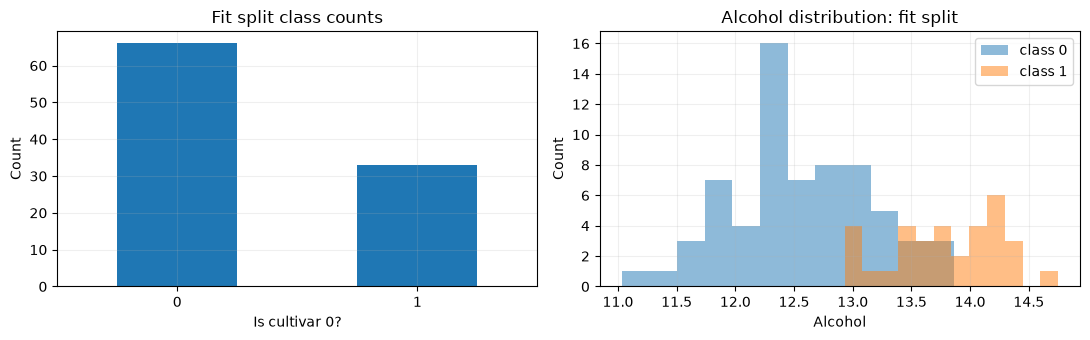

In [3]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED + 1)
assert set(X_fit.index).isdisjoint(X_val.index)
display(X_fit.describe().T[["mean", "std", "min", "max"]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
y_fit.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Fit split class counts", xlabel="Is cultivar 0?", ylabel="Count")
for label in [0, 1]:
    axes[1].hist(X_fit.loc[y_fit == label, "alcohol"], alpha=0.5, bins=12, label=f"class {label}")
axes[1].set(title="Alcohol distribution: fit split", xlabel="Alcohol", ylabel="Count")
axes[1].legend(); plt.tight_layout(); plt.show()


## 2. Почему логистическая регрессия — классификатор

$$z=w^Tx+b,\quad p(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}.$$
$$L=-\frac1n\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)].$$

Модель оценивает вероятность; отдельное правило `p >= threshold` выдаёт класс.
Log loss штрафует уверенные ошибочные вероятности сильнее. Численно устойчивый
binary log loss можно записать через `logaddexp`, без `log(0)`.


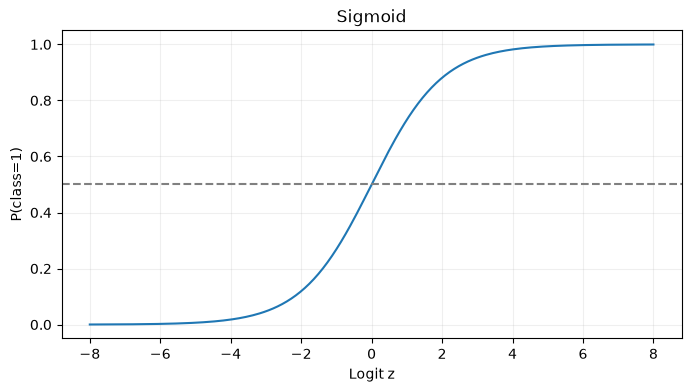

In [4]:
from scipy.special import expit
z_grid = np.linspace(-8, 8, 250)
def binary_loss_from_logits(y_true, logits):
    return np.mean(np.logaddexp(0.0, logits) - np.asarray(y_true) * logits)
assert np.isfinite(binary_loss_from_logits(np.array([0, 1]), np.array([-1000., 1000.])))
plt.plot(z_grid, expit(z_grid)); plt.axhline(0.5, ls="--", color="gray")
plt.xlabel("Logit z"); plt.ylabel("P(class=1)"); plt.title("Sigmoid"); plt.show()


## 3. Базовая логистическая модель

Scaler находится внутри Pipeline. Коэффициенты регуляризуются; `C` — обратная
сила регуляризации. Для первой модели фиксируем `C=1`, не подбирая его на test.
Отдельно обучаем baseline, который всегда выбирает наиболее частый класс.


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, log_loss
logistic = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1500, random_state=SEED))
logistic.fit(X_fit, y_fit)
baseline = DummyClassifier(strategy="most_frequent").fit(X_fit, y_fit)
val_probability = logistic.predict_proba(X_val)[:, 1]
assert np.all((val_probability >= 0) & (val_probability <= 1))
assert np.allclose(logistic.predict_proba(X_val).sum(axis=1), 1)
print("Baseline validation accuracy:", accuracy_score(y_val, baseline.predict(X_val)))
print("Logistic validation log loss:", log_loss(y_val, val_probability))


Baseline validation accuracy: 0.6764705882352942
Logistic validation log loss: 0.041578462483273064


## 4. Порог — решение с ценой ошибок

Для учебного сценария пропуск положительного образца (FN) стоит 3 условные
единицы, ложный сигнал (FP) — 1. Это явное допущение, не свойство Wine.
Выберем порог на validation по минимальной стоимости. Самые низкие значения
на маленькой validation могут быть случайностью; используем заранее заданную сетку.


In [6]:
from sklearn.metrics import confusion_matrix
thresholds = np.linspace(0.1, 0.9, 17)
threshold_rows = []
for threshold in thresholds:
    pred = (val_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    threshold_rows.append({"threshold": threshold, "FP": fp, "FN": fn,
                           "cost_per_sample": (fp + 3 * fn) / len(y_val)})
threshold_table = pd.DataFrame(threshold_rows)
# При равенстве стоимости выбираем порог ближе к 0.5: правило задано заранее.
selected_threshold = threshold_table.assign(distance=(threshold_table.threshold - 0.5).abs())        .sort_values(["cost_per_sample", "distance"]).iloc[0]["threshold"]
display(threshold_table)
print("Зафиксированный порог:", selected_threshold)


,threshold,FP,FN,cost_per_sample
0,0.10,1,0,0.029412
1,0.15,0,0,0.000000
2,0.20,0,0,0.000000
3,0.25,0,0,0.000000
4,0.30,0,0,0.000000
5,0.35,0,0,0.000000
6,0.40,0,0,0.000000
7,0.45,0,0,0.000000
8,0.50,0,0,0.000000
9,0.55,0,0,0.000000


Зафиксированный порог: 0.5


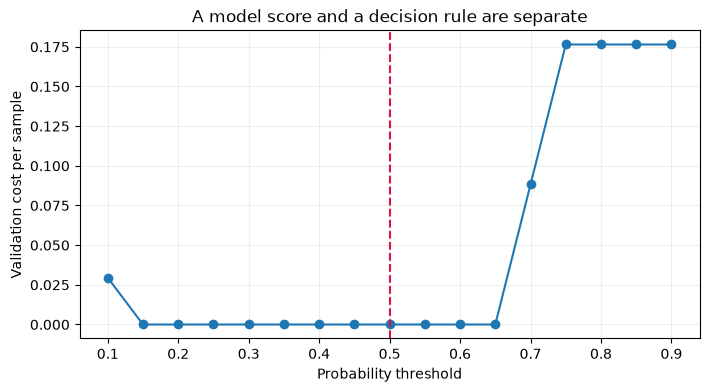

In [7]:
plt.plot(threshold_table.threshold, threshold_table.cost_per_sample, marker="o")
plt.axvline(selected_threshold, color="crimson", ls="--")
plt.xlabel("Probability threshold"); plt.ylabel("Validation cost per sample")
plt.title("A model score and a decision rule are separate"); plt.show()


## 5. kNN: учимся читать расстояния

$$d(x,x')=\sqrt{\sum_j(x_j-x'_j)^2},\qquad
\hat p(y=1\mid x)=\frac1k\sum_{i\in N_k(x)}y_i.$$

Если шкала `proline` на порядки крупнее `hue`, она может определять соседей.
На одной validation сравним заранее заданные варианты: raw kNN и scaled kNN.
Это объяснительный опыт; k выбирается дальше на CV, а не по test.


In [8]:
from sklearn.neighbors import KNeighborsClassifier
raw_knn = KNeighborsClassifier(n_neighbors=5).fit(X_fit, y_fit)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_fit, y_fit)
comparison = pd.DataFrame([
    {"model": "raw kNN, k=5", "validation balanced accuracy": balanced_accuracy_score(y_val, raw_knn.predict(X_val))},
    {"model": "scaled kNN, k=5", "validation balanced accuracy": balanced_accuracy_score(y_val, scaled_knn.predict(X_val))}])
display(comparison)


,model,validation balanced accuracy
0,"raw kNN, k=5",0.863636
1,"scaled kNN, k=5",1.000000


## 6. Один прогноз kNN вручную

Найдём соседей первого **validation**, а не test, объекта. Средняя метка
соседей должна совпасть с `predict_proba` при uniform weights. Расстояния
вычисляются после scaler, который видел только fit.


In [9]:
scaled_fit = scaled_knn[0].transform(X_fit)
query = scaled_knn[0].transform(X_val.iloc[[0]])[0]
distances = np.linalg.norm(scaled_fit - query, axis=1)
neighbor_positions = np.argsort(distances)[:5]
manual_probability = y_fit.iloc[neighbor_positions].mean()
library_probability = scaled_knn.predict_proba(X_val.iloc[[0]])[0, 1]
assert np.isclose(manual_probability, library_probability)
display(pd.DataFrame({"sample_id": X_fit.index[neighbor_positions],
                      "distance": distances[neighbor_positions],
                      "label": y_fit.iloc[neighbor_positions].to_numpy()}))
print("P(class=1):", manual_probability)


,sample_id,distance,label
0,150,2.320998,0
1,149,2.719694,0
2,152,2.844549,0
3,147,3.130055,0
4,148,3.135270,0


P(class=1): 0.0


## 7. Подбор k на CV только внутри train

На каждом fold scaler переобучается. Слишком маленькое k повышает чувствительность
к шуму; большое k сглаживает границу. Сравниваем mean и разброс, а не только победителя.
После CV kNN переобучится на всём train. Logistic сохраняем в виде `fit + threshold`:
переобучение после подбора порога может изменить распределение вероятностей.


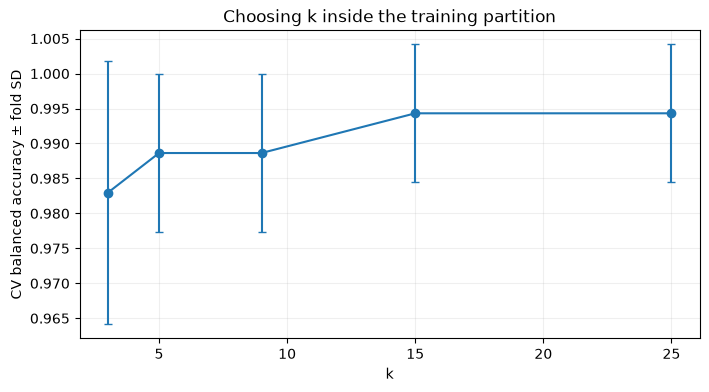

{'kneighborsclassifier__n_neighbors': 15}


In [10]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": [3, 5, 9, 15, 25]},
                      cv=cv, scoring="balanced_accuracy", n_jobs=1)
search.fit(X_train, y_train)
results = pd.DataFrame(search.cv_results_)
plt.errorbar(results["param_kneighborsclassifier__n_neighbors"].astype(int),
             results.mean_test_score, yerr=results.std_test_score, marker="o", capsize=3)
plt.xlabel("k"); plt.ylabel("CV balanced accuracy ± fold SD")
plt.title("Choosing k inside the training partition"); plt.show()
print(search.best_params_)


## 8. Финальный holdout: фиксируем обе модели

Мы не объявляем победителя по test и не меняем порог после просмотра.
Logistic обучалась на fit; kNN после CV использует полный train: бюджеты
обучения отличаются, это честно отмечаем. Test невелик, поэтому одна ошибка
может заметно изменить итоговую оценку.


In [11]:
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
p_logistic = logistic.predict_proba(X_test)[:, 1]
p_knn = search.predict_proba(X_test)[:, 1]
rows = []
for name, probabilities, threshold in [
    ("Logistic + validation threshold", p_logistic, selected_threshold),
    ("Scaled kNN + CV", p_knn, 0.5)]:
    pred = (probabilities >= threshold).astype(int)
    rows.append({"model": name, "threshold": threshold,
                 "accuracy": accuracy_score(y_test, pred),
                 "balanced_accuracy": balanced_accuracy_score(y_test, pred),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "ROC AUC": roc_auc_score(y_test, probabilities),
                 "log_loss": log_loss(y_test, probabilities)})
display(pd.DataFrame(rows).round(3))
assert np.isfinite(pd.DataFrame(rows).select_dtypes("number")).all().all()


,model,threshold,accuracy,balanced_accuracy,F1,ROC AUC,log_loss
0,Logistic + validation threshold,0.5,1.000,1.000,1.000,1.000,0.055
1,Scaled kNN + CV,0.5,0.978,0.983,0.968,0.996,0.085


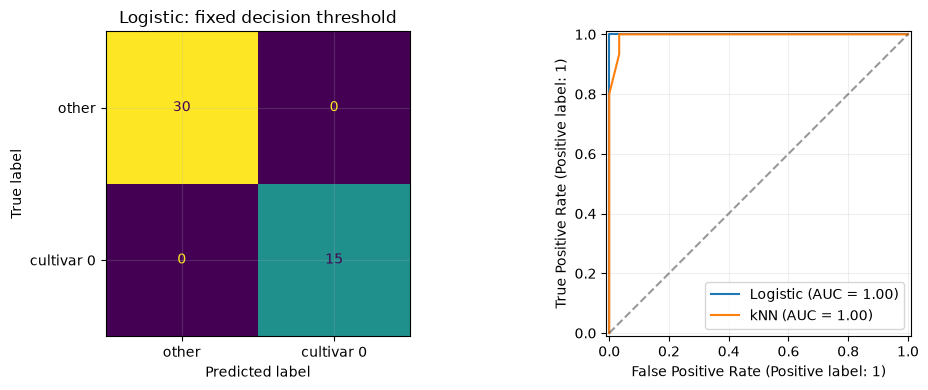

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (p_logistic >= selected_threshold).astype(int),
                                        display_labels=["other", "cultivar 0"], ax=axes[0], colorbar=False)
axes[0].set_title("Logistic: fixed decision threshold")
RocCurveDisplay.from_predictions(y_test, p_logistic, name="Logistic", ax=axes[1])
RocCurveDisplay.from_predictions(y_test, p_knn, name="kNN", ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.tight_layout(); plt.show()


## Самопроверка

- При изменении порога меняется ли ROC AUC для уже рассчитанных вероятностей? Почему?
- Почему accuracy может скрывать пропуски редкого класса?
- Что произойдёт с raw kNN, если измерять один признак в тысячных долях исходной единицы?
- Объясните, почему `target` исходной трёхклассовой задачи нельзя оставить в X.

Источники: [Stanford CS229 notes](https://cs229.stanford.edu/main_notes.pdf),
[LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
[nearest neighbors](https://scikit-learn.org/stable/modules/neighbors.html),
[decision threshold](https://scikit-learn.org/stable/modules/classification_threshold.html).
